## Lab 6 UCL OPM MEG Data Exploration and Denoising

Work will follow general good practice for reporting MEG research and OPM MEG specfic research using single subject UCL OPM MEG dataset downloaded from MNE Python.

### Data Visualization
Look at the raw data and note features without performing denoising just yet.

1. Raw data
2. View power spectrum to find sources of noise
3. Setting up Evoked response (no denoising)
4. Visualizing spatial tomography

### Denoising

Denoising is performed after sources of noise are identified. First, manual inspection and automatic detection of bad sensor channels is performed so that they do not bias denoising methods. Regression via reference sensors and HFC are compared, but we will use HFC. Filtering is then applied to remove power line noise via a notch filter and a high pass filter is also applied to increase SNR by reducing muscle and eye artifacts in the time domain.

1. equipment noise 
2. external noise (HFC vs regression with reference sensors)
3. physiological noise


### Evoked Response and Source Estimate

1. Viewing evoked response with varying denoising parameters
2. MNE estimate calculated and compared for varying parameters

### -----------------------------------------------------------------------

### Accessing Data

In [13]:
# Accessing Data and Exploring

import matplotlib.pyplot as plt
import numpy as np
import nibabel as nib
import mne

data_path = mne.datasets.ucl_opm_auditory.data_path()
subject = "sub-002"
opm_file = (
    data_path / subject / "ses-001" / "meg" / "sub-002_ses-001_task-aef_run-001_meg.bin"
)
subjects_dir = data_path / "derivatives" / "freesurfer" / "subjects"

# For now we are going to assume the device and head coordinate frames are
# identical (even though this is incorrect), so we pass verbose='error'
raw = mne.io.read_raw_fil(opm_file, verbose="error")
raw.crop(120, 210).load_data()  # crop for speed


Reading 0 ... 540000  =      0.000 ...    90.000 secs...


<RawFIL | sub-002_ses-001_task-aef_run-001_meg.bin, 95 x 540001 (90.0 s), ~391.5 MiB, data loaded>

### Viewing Raw Data

#### Power spectrum of raw data

Note the power line noise and harmonics at 50Hz and 100 Hz and the 120 Hz OptiTrack Camera noise contrributions

Effective window size : 0.341 (s)
Plotting power spectral density (dB=True).


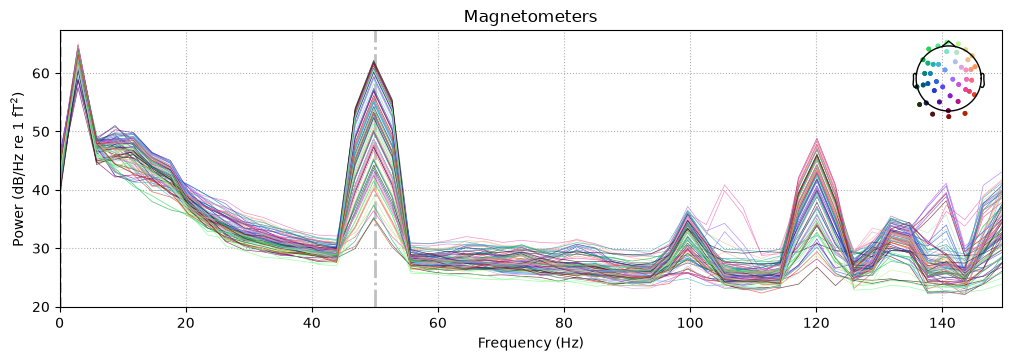

Effective window size : 0.341 (s)
Plotting power spectral density (dB=True).


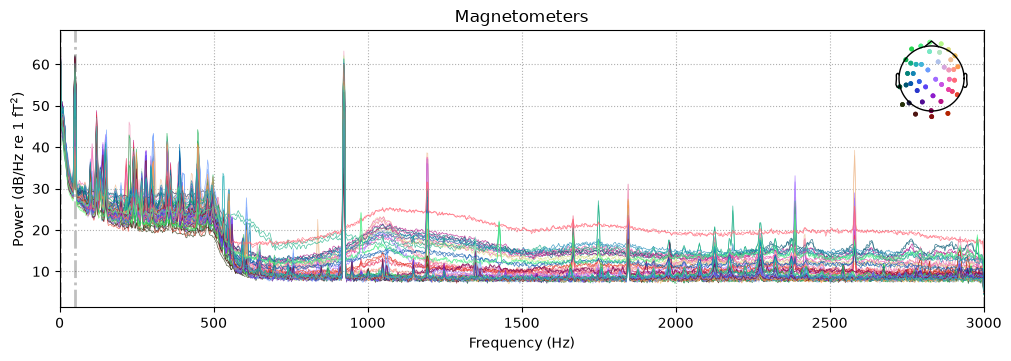

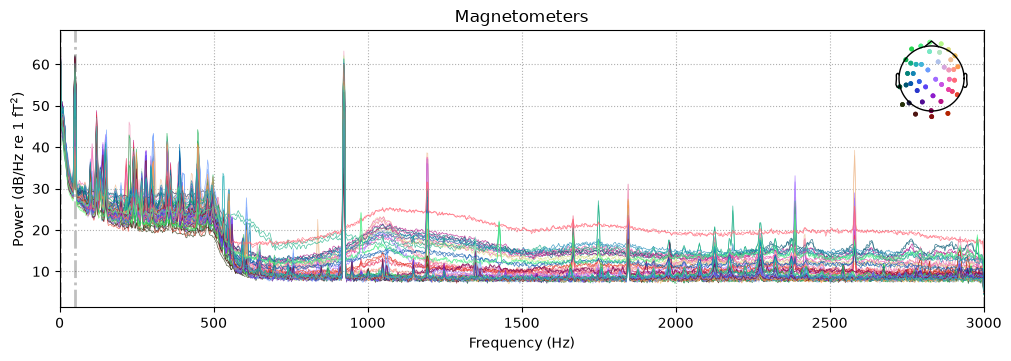

In [14]:
# First, power spectrum of raw data

raw.compute_psd(fmax=150).plot(picks="data", exclude="bads", amplitude=False)
raw.compute_psd().plot(picks="data", exclude="bads", amplitude=False)

[Text(0.5, 1.0, 'Sampled Data without mean subtraction'),
 (-1000.0, 1000.0),
 (0.0, 89.91666666666667),
 Text(0.5, 0, 'Time (s)'),
 Text(0, 0.5, 'Amplitude (pT)')]

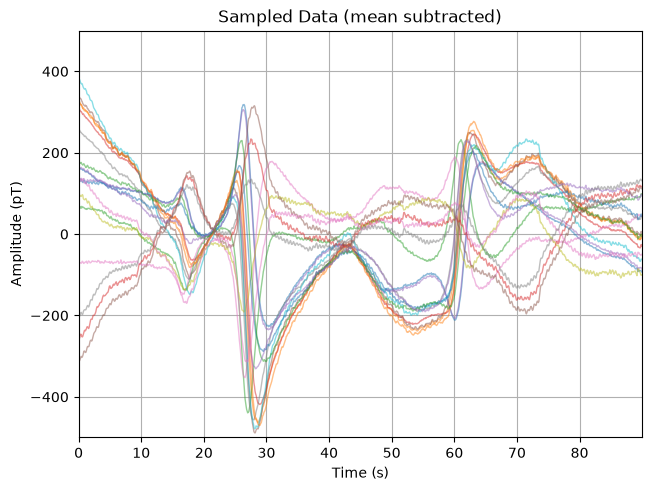

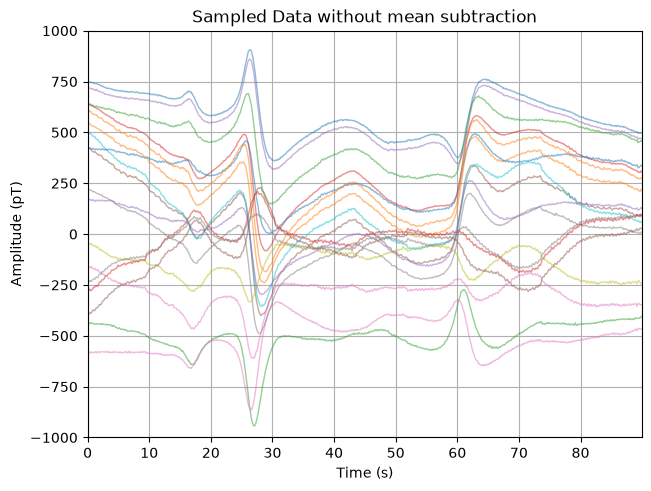

In [15]:
# Denoising Data

# Inspecting raw unprocessed data

picks = mne.pick_types(raw.info, meg=True) # this picks all MEG channels

amp_scale = 1e12  # T->pT
stop = len(raw.times) - 300
step = 500
data_ds, time_ds = raw[picks[::5], :stop]
data_ds, time_ds = data_ds[:, ::step] * amp_scale, time_ds[::step]

fig, ax = plt.subplots(layout="constrained")
plot_kwargs = dict(lw=1, alpha=0.5)
ax.plot(time_ds, data_ds.T - np.mean(data_ds, axis=1), **plot_kwargs)
ax.grid(True)
set_kwargs = dict(
    ylim=(-500, 500), xlim=time_ds[[0, -1]], xlabel="Time (s)", ylabel="Amplitude (pT)"
)
ax.set(title="Sampled Data (mean subtracted)", **set_kwargs)


picks = mne.pick_types(raw.info, meg=True) # this picks all MEG channels

amp_scale = 1e12  # T->pT
stop = len(raw.times) - 300
step = 500
data_ds, time_ds = raw[picks[::5], :stop]
data_ds, time_ds = data_ds[:, ::step] * amp_scale, time_ds[::step]

fig, ax = plt.subplots(layout="constrained")
plot_kwargs = dict(lw=1, alpha=0.5)
ax.plot(time_ds, data_ds.T, **plot_kwargs)
ax.grid(True)
set_kwargs = dict(
    ylim=(-1000, 1000), xlim=time_ds[[0, -1]], xlabel="Time (s)", ylabel="Amplitude (pT)"
)
ax.set(title="Sampled Data without mean subtraction", **set_kwargs)


### Evoked (noisy data)

Finding events on: NI-TRIG
180 events found on stim channel NI-TRIG
Event IDs: [3]
No projector specified for this dataset. Please consider the method self.add_proj.


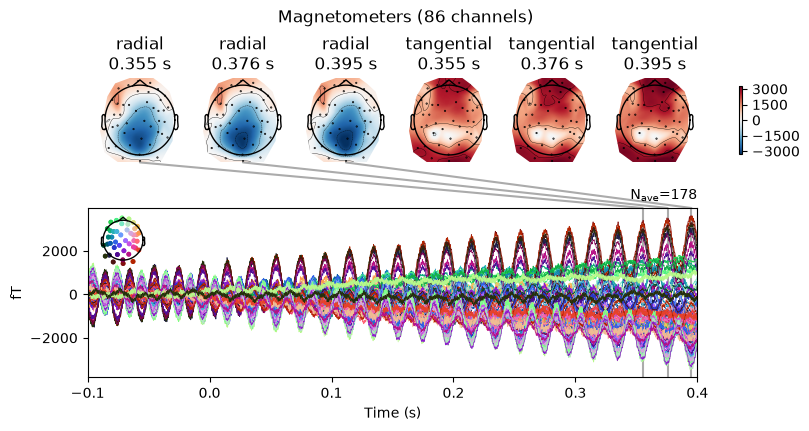

In [16]:
events = mne.find_events(raw, min_duration=0.1)
epochs = mne.Epochs(
    raw, events, tmin=-0.1, tmax=0.4, baseline=(-0.1, 0.0), verbose="error"
)
evoked = epochs.average()
t_peak = evoked.times[np.argmax(np.std(evoked.copy().pick("meg").data, axis=0))]
fig = evoked.plot_joint(picks="mag")

# Powerline noise is all that is visible when plotting the evoked signal

#### Notes on Noise

The powerline noise is the most dominant feature. 

### Denoising

First regression via HFC is compared to regression using reference sensors

Effective window size : 1.000 (s)
Filtering a subset of channels. The highpass and lowpass values in the measurement info will not be updated.
Filtering raw data in 1 contiguous segment
Setting up low-pass filter at 5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal lowpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Upper passband edge: 5.00 Hz
- Upper transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 6.00 Hz)
- Filter length: 9901 samples (1.650 s)

No projector specified for this dataset. Please consider the method self.add_proj.
No projector specified for this dataset. Please consider the method self.add_proj.
Effective window size : 1.000 (s)


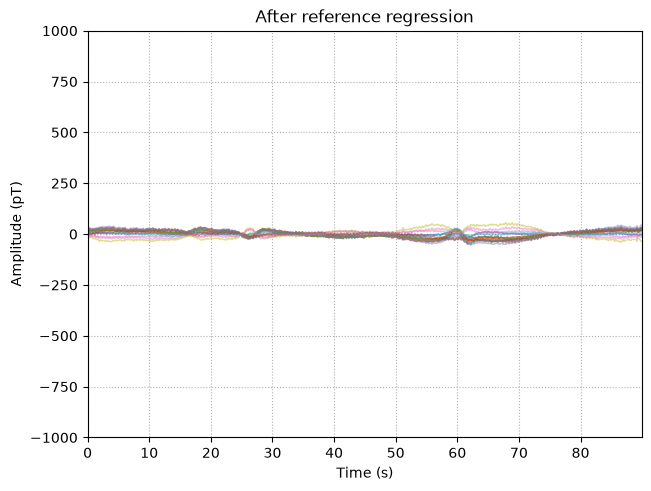

In [17]:
# set flux channels to bad
bad_picks = mne.pick_channels_regexp(raw.ch_names, regexp="Flux.")
raw.info["bads"].extend([raw.ch_names[ii] for ii in bad_picks])
raw.info["bads"].extend(["G2-17-TAN"])

# compute the PSD for later using 1 Hz resolution
psd_kwargs = dict(fmax=20, n_fft=int(round(raw.info["sfreq"])))
psd_pre = raw.compute_psd(**psd_kwargs)

# filter and regress
raw.filter(None, 5, picks="ref_meg")
regress = mne.preprocessing.EOGRegression(picks, picks_artifact="ref_meg")
regress.fit(raw)
regress.apply(raw, copy=False)

# plot
data_ds, _ = raw[picks[::5], :stop]
data_ds = data_ds[:, ::step] * amp_scale

fig, ax = plt.subplots(layout="constrained")
ax.plot(time_ds, data_ds.T - np.mean(data_ds, axis=1), **plot_kwargs)
ax.grid(True, ls=":")
ax.set(title="After reference regression", **set_kwargs)

# compute the psd of the regressed data
psd_post_reg = raw.compute_psd(**psd_kwargs)

8 projection items deactivated
Effective window size : 1.000 (s)


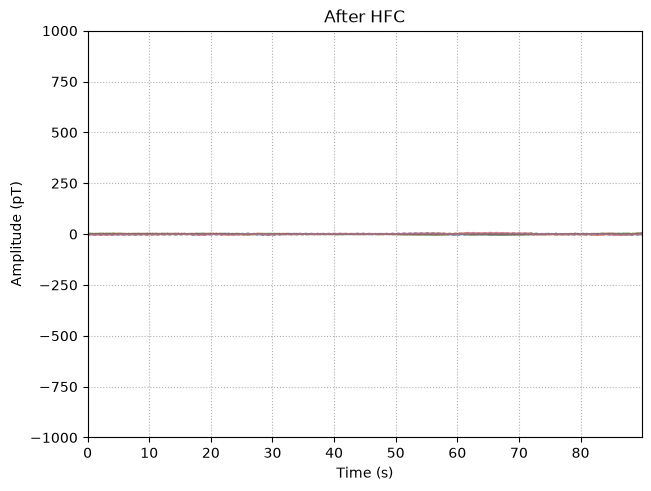

In [18]:
# include gradients by setting order to 2, set to 1 for homogeneous components
projs = mne.preprocessing.compute_proj_hfc(raw.info, order=2)
raw.add_proj(projs).apply_proj(verbose="error")

# plot
data_ds, _ = raw[picks[::5], :stop]
data_ds = data_ds[:, ::step] * amp_scale

fig, ax = plt.subplots(layout="constrained")
ax.plot(time_ds, data_ds.T - np.mean(data_ds, axis=1), **plot_kwargs)
ax.grid(True, ls=":")
ax.set(title="After HFC", **set_kwargs)

# compute the psd of the regressed data
psd_post_hfc = raw.compute_psd(**psd_kwargs)

####  comparing denoising methods

[(0.0, 20.0),
 Text(0.5, 1.0, 'Reference regression & HFC shielding'),
 Text(0.5, 0, 'Frequency (Hz)'),
 Text(0, 0.5, 'Shielding (dB)')]

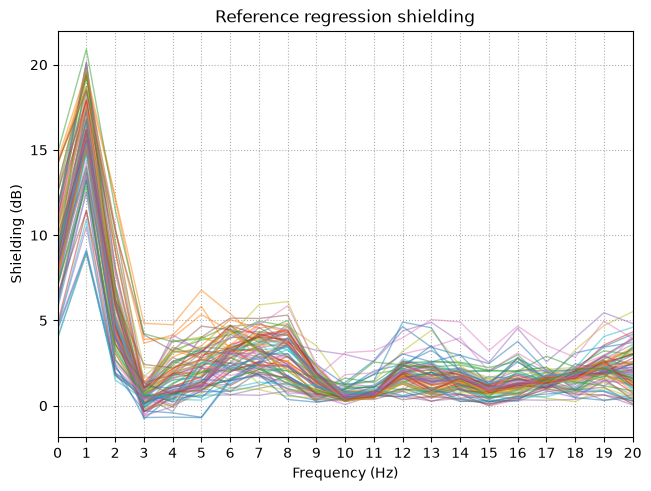

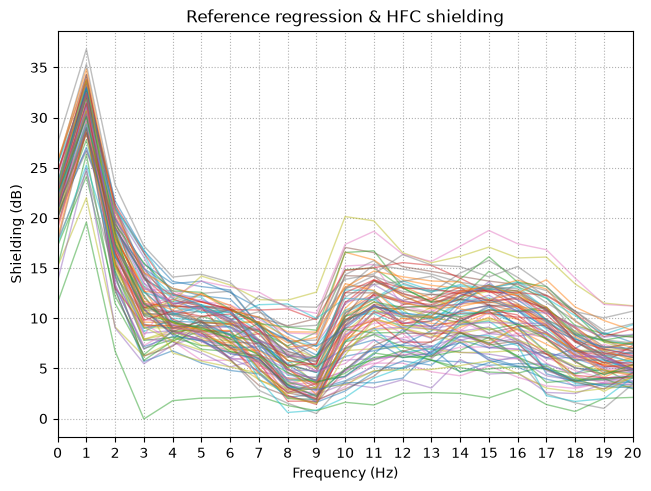

In [19]:
shielding = 10 * np.log10(psd_pre[:] / psd_post_reg[:])

fig, ax = plt.subplots(layout="constrained")
ax.plot(psd_post_reg.freqs, shielding.T, **plot_kwargs)
ax.grid(True, ls=":")
ax.set(xticks=psd_post_reg.freqs)
ax.set(
    xlim=(0, 20),
    title="Reference regression shielding",
    xlabel="Frequency (Hz)",
    ylabel="Shielding (dB)",
)


shielding = 10 * np.log10(psd_pre[:] / psd_post_hfc[:])

fig, ax = plt.subplots(layout="constrained")
ax.plot(psd_post_hfc.freqs, shielding.T, **plot_kwargs)
ax.grid(True, ls=":")
ax.set(xticks=psd_post_hfc.freqs)
ax.set(
    xlim=(0, 20),
    title="Reference regression & HFC shielding",
    xlabel="Frequency (Hz)",
    ylabel="Shielding (dB)",
)

### Filtering (e.g. powerline noise and low freq. contaminated with physiological artifacts)


Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower transition bandwidth: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz
- Filter length: 39601 samples (6.600 s)

Filtering a subset of channels. The highpass and lowpass values in the measurement info will not be updated.
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 2 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 2.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 1.00 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwid

[Text(0.5, 1.0, 'After regression, HFC and filtering'),
 (-500.0, 500.0),
 (0.0, 89.91666666666667),
 Text(0.5, 0, 'Time (s)'),
 Text(0, 0.5, 'Amplitude (pT)')]

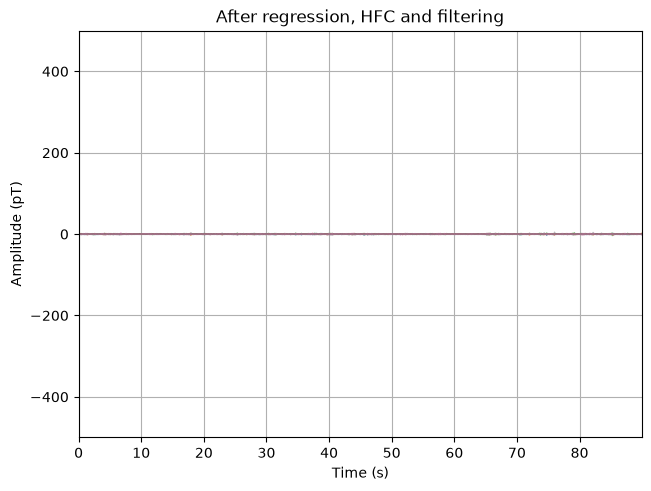

In [20]:

# notch
raw.notch_filter(np.arange(50, 251, 50), notch_widths=4)
# bandpass
raw.filter(2, 40, picks="meg")
# plot
data_ds, _ = raw[picks[::5], :stop]
data_ds = data_ds[:, ::step] * amp_scale
fig, ax = plt.subplots(layout="constrained")
plot_kwargs = dict(lw=1, alpha=0.5)
ax.plot(time_ds, data_ds.T - np.mean(data_ds, axis=1), **plot_kwargs)
ax.grid(True)
set_kwargs = dict(
    ylim=(-500, 500), xlim=time_ds[[0, -1]], xlabel="Time (s)", ylabel="Amplitude (pT)"
)
ax.set(title="After regression, HFC and filtering", **set_kwargs)

Finding events on: NI-TRIG
180 events found on stim channel NI-TRIG
Event IDs: [3]
Projections have already been applied. Setting proj attribute to True.


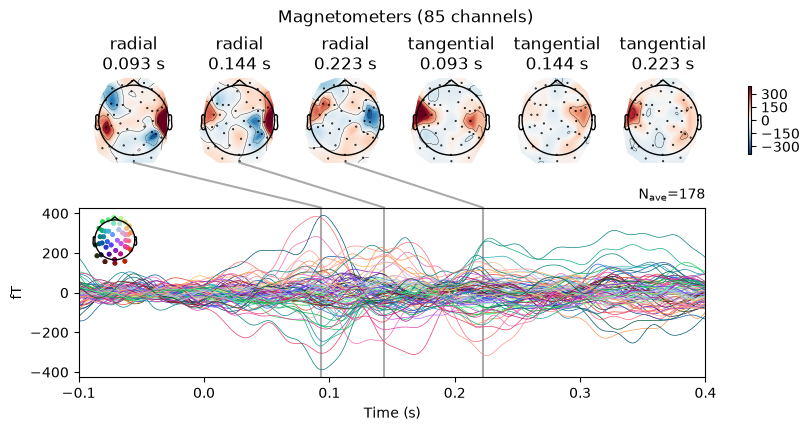

In [21]:
events = mne.find_events(raw, min_duration=0.1)
epochs = mne.Epochs(
    raw, events, tmin=-0.1, tmax=0.4, baseline=(-0.1, 0.0), verbose="error"
)
evoked = epochs.average()
t_peak = evoked.times[np.argmax(np.std(evoked.copy().pick("meg").data, axis=0))]
fig = evoked.plot_joint(picks="mag")

In [26]:
# Getting trans and bem
%matplotlib inline
mri = nib.load(subjects_dir / "sub-002" / "mri" / "T1.mgz")
trans = mri.header.get_vox2ras_tkr() @ np.linalg.inv(mri.affine)
trans[:3, 3] /= 1000.0  # nibabel uses mm, MNE uses m
trans = mne.transforms.Transform("head", "mri", trans)
bem = subjects_dir / subject / "bem" / f"{subject}-5120-bem-sol.fif"
src = subjects_dir / subject / "bem" / f"{subject}-oct-6-src.fif"

### Plotting Source Estimate

In [27]:
fwd = mne.make_forward_solution(
    evoked.info,
    trans=trans,
    bem=bem,
    src=src,
    verbose=True,
)

noise_cov = mne.compute_covariance(epochs, tmax=0)
inv = mne.minimum_norm.make_inverse_operator(evoked.info, fwd, noise_cov, verbose=True)
stc = mne.minimum_norm.apply_inverse(
    evoked, inv, 1.0 / 9.0, method="dSPM", verbose=True
)
brain = stc.plot(
    hemi="split",
    size=(800, 400),
    initial_time=t_peak,
    subjects_dir=subjects_dir,
)

Source space          : /home/jovyan/mne_data/auditory_OPM_stationary/derivatives/freesurfer/subjects/sub-002/bem/sub-002-oct-6-src.fif
MRI -> head transform : instance of Transform
Measurement data      : instance of Info
Conductor model   : /home/jovyan/mne_data/auditory_OPM_stationary/derivatives/freesurfer/subjects/sub-002/bem/sub-002-5120-bem-sol.fif
Accurate field computations
Do computations in head coordinates
Free source orientations

Reading /home/jovyan/mne_data/auditory_OPM_stationary/derivatives/freesurfer/subjects/sub-002/bem/sub-002-oct-6-src.fif...
Read 2 source spaces a total of 8196 active source locations

Coordinate transformation: MRI (surface RAS) -> head
    1.000000 0.000000 0.000000       0.50 mm
    0.000000 1.000000 0.000000      26.98 mm
    0.000000 0.000000 1.000000      -9.21 mm
    0.000000 0.000000 0.000000       1.00

Read 94 MEG channels from info
Read 8 MEG compensation channels from info
0 compensation data sets in info
Setting up compensation data.

RuntimeError: Could not load any valid 3D backend
pyvistaqt: No module named 'qtpy'
notebook: No module named 'ipyevents'

 install pyvistaqt, using pip or conda:
'pip install pyvistaqt'
'conda install -c conda-forge pyvistaqt'

 or install ipywidgets, if using a notebook backend
'pip install ipywidgets'
'conda install -c conda-forge ipywidgets'